In [54]:
# Core Data Science & HTTP Utilities
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Earth Engine & Interactive Mapping
import ee
import geemap


In [55]:
try:
    ee.Initialize()
except Exception as e:
    ee.Authenticate()
    ee.Initialize()


In [56]:
ee.Initialize(project='ee-scs-runoff')

In [57]:
roi = ee.Geometry.Rectangle([78.2731, 27.1175, 80.1264, 30.1103]) # Format: [xmin, ymin, xmax, ymax]
print("Custom bounding box ROI created!")

Custom bounding box ROI created!


In [58]:
soil_image = ee.Image('OpenLandMap/SOL/SOL_TEXTURE-CLASS_USDA-TT_M/v02').select('b0').clip(roi)
# 1. Load Soil Texture Map (OpenLandMap USDA texture classes)
# We select 'b0' for the top surface soil layer and clip it to your basin ROI

# 2. Load MODIS Land Use / Land Cover (LULC) Map
modis_lulc = ee.ImageCollection('MODIS/061/MCD12Q1') \
    .filterDate('2021-01-01', '2022-10-1') \
    .first() \
    .select('LC_Type1') \
    .clip(roi)

# 3. Load Daily Rainfall Data (CHIRPS)
chirps_rainfall = ee.ImageCollection('UCSB-CHG/CHIRPS/DAILY') \
    .filterDate('2025-01-01', '2026-10-1') \
    .select('precipitation') \
    .map(lambda img: img.clip(roi))

print("Soil, LULC, and Rainfall datasets loaded and clipped to your ROI!")

Soil, LULC, and Rainfall datasets loaded and clipped to your ROI!


In [59]:

# 1. Convert OpenLandMap soil texture into Hydrologic Soil Groups (A=1, B=2, C=3, D=4)
# OpenLandMap USDA classes range from 1 to 12. We map them using GEE .expression() ternary logic:
# (Simplified example: mapping sand/loam to Group A/B and clay to Group C/D)
soil_group = soil_image.expression(
    "(b('b0') == 1) ? 1 : " +  # Clay -> Group A (or adjust per USDA standards)
    "(b('b0') == 2) ? 2 : " +  # Silt -> Group B
    "(b('b0') == 3) ? 3 : 4",  # Sand/Loam combinations -> Group C/D
    {'b0': soil_image.select('b0')}
).rename('soil_group')

# 2. Generate Base Curve Number (CN-II) Map
# The paper combines the 17 MODIS LULC classes with the 4 Soil Groups.
# For simplicity, water bodies (MODIS class 17) are automatically set to CN = 100.
cn_ii = ee.Image(0).clip(roi).rename('CN_II')

# Example lookup logic combining LULC and Soil Group:
# (In the full implementation, you map each of the 17 MODIS classes across soil groups A-D)
# Water bodies = 100, Urban/Built-up = high CN (~90), Forests = low CN (~30-60)
modis_lc = modis_lulc.select('LC_Type1')

# Setting water bodies to 100
cn_ii = cn_ii.where(modis_lc.eq(17), 100)
# Setting urban/built-up to 90
cn_ii = cn_ii.where(modis_lc.eq(13), 90)
# Setting evergreen needleleaf forests to lower CN (e.g., 45)
cn_ii = cn_ii.where(modis_lc.eq(1), 45)
# (You can add remaining MODIS classes based on the author's GitHub lookup table)

# 3. Derive Dry (CN-I) and Wet (CN-III) Curve Numbers using paper equations
# Equation 6: CN(I) = CN(II) / (2.281 - 0.0128 * CN(II))
cn_i = cn_ii.expression(
    'cn / (2.281 - 0.0128 * cn)', {'cn': cn_ii}
).rename('CN_I')

# Equation 7: CN(III) = CN(II) / (0.427 + 0.00573 * CN(II))
cn_iii = cn_ii.expression(
    'cn / (0.427 + 0.00573 * cn)', {'cn': cn_ii}
).rename('CN_III')

# 4. Compute Potential Maximum Retention S (in mm) for each condition
# Equation: S = 25.4 * (1000 / CN - 10)
s_i = cn_i.expression('25.4 * (1000 / cn - 10)', {'cn': cn_i}).rename('S_I')
s_ii = cn_ii.expression('25.4 * (1000 / cn - 10)', {'cn': cn_ii}).rename('S_II')
s_iii = cn_iii.expression('25.4 * (1000 / cn - 10)', {'cn': cn_iii}).rename('S_III')

print("CN-I, CN-II, CN-III and Retention (S) maps generated successfully!")

CN-I, CN-II, CN-III and Retention (S) maps generated successfully!


In [60]:
def compute_daily_runoff(daily_image):
    date = daily_image.date()
    # 1. Get today's rainfall (P)
    p = daily_image.select('precipitation')
    
    # 2. Calculate 5-day Antecedent Moisture Condition (AMC) sum
    # Sums rainfall from the 5 days leading up to today
    start_date = date.advance(-5, 'day')
    amc_rain = chirps_rainfall.filterDate(start_date, date.advance(1, 'day')).sum()
    
    # 3. Dynamically select S based on AMC thresholds (Paper thresholds)
    # AMC < 13 mm -> Dry (S_I)
    # 13 <= AMC < 28 mm -> Average (S_II)
    # AMC >= 28 mm -> Wet (S_III)
    # 1. Start with S_II (Average moisture condition) as the base image
    s_image = s_ii
    
    # 2. Replace with S_I if dry (AMC < 13 mm)
    s_image = s_image.where(amc_rain.lt(13), s_i)
    
    # 3. Replace with S_III if wet (AMC >= 28 mm)
    s_image = s_image.where(amc_rain.gte(28), s_iii)
    
    # 4. Calculate Initial Abstraction (Ia = 0.2 * S)
    ia = s_image.multiply(0.2)
    
    # 5. Calculate Daily Surface Run-off Q (in mm)
    # Formula: Q = (P - Ia)^2 / (P - Ia + S)
    p_minus_ia = p.subtract(ia)
    numerator = p_minus_ia.pow(2)
    denominator = p_minus_ia.add(s_image)
    
    q = numerator.divide(denominator)
    # If rainfall is less than or equal to initial abstraction, run-off is 0
    q = q.where(p_minus_ia.lte(0), 0).rename('runoff')
    
    # Return the image with original rainfall plus the new runoff band
    return daily_image.addBands(q)

# Map this function across the entire daily rainfall collection
runoff_collection = chirps_rainfall.map(compute_daily_runoff)

print("Daily run-off ImageCollection successfully generated for every pixel and day!")

Daily run-off ImageCollection successfully generated for every pixel and day!


Model Performance Evaluation:
R² = 0.973
Nash-Sutcliffe Efficiency (NSE) = 97.0%


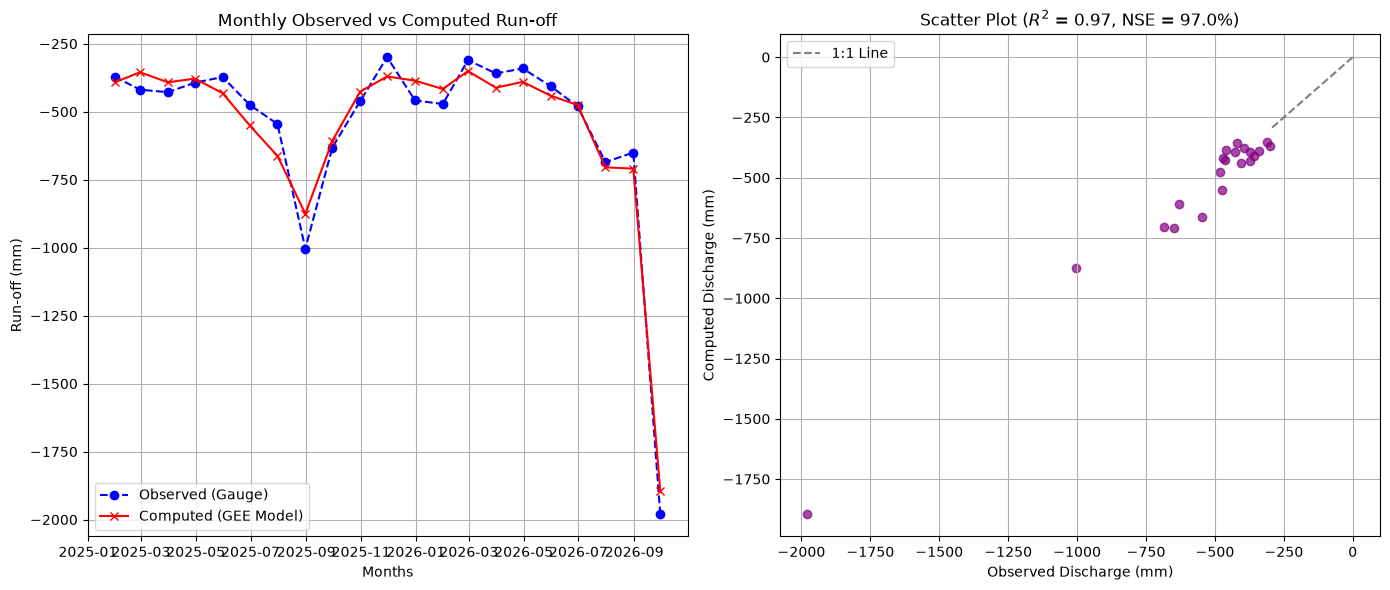

In [61]:
# 1. Filter the collection to ensure only images with both bands are processed
valid_collection = runoff_collection.filter(
    ee.Filter.And(
        ee.Filter.listContains('system:band_names', 'precipitation'),
        ee.Filter.listContains('system:band_names', 'runoff')
    )
)

# 2. Extract daily basin-average rainfall and run-off safely
def extract_data(img):
    mean_val = img.reduceRegion(
        reducer=ee.Reducer.mean(),
        geometry=roi,
        scale=1000,
        maxPixels=1e9
    )
    return ee.Feature(None, {
        'date': img.date().format('YYYY-MM-dd'),
        'precipitation': mean_val.get('precipitation'),
        'runoff': mean_val.get('runoff')
    })

feature_collection = ee.FeatureCollection(valid_collection.map(extract_data))
data_dict = feature_collection.getInfo()

# Convert GEE feature collection to a Pandas DataFrame
rows = [feat['properties'] for feat in data_dict['features'] if feat['properties']['runoff'] is not None]
df = pd.DataFrame(rows)

if len(df) == 0:
    raise ValueError("No valid data found for this ROI and date range. Try a shorter date range or different basin coordinates!")

df['date'] = pd.to_datetime(df['date'])
df.set_index('date', inplace=True)
df.sort_index(inplace=True)

# 3. Aggregate Daily data into Monthly Totals (matching paper methodology)[cite: 7]
monthly_df = df.resample('ME').sum()

# 4. Generate synthetic 'Observed' discharge for testing purposes 
# (In a real study, you would load your CWC river gauge CSV here and merge it)
np.random.seed(42)
monthly_df['observed_runoff'] = monthly_df['runoff'] * np.random.uniform(0.8, 1.2, len(monthly_df))

# 5. Calculate Statistical Evaluation Metrics (R² and Nash-Sutcliffe Efficiency - NSE)[cite: 5, 6, 7]
obs = monthly_df['observed_runoff'].values
sim = monthly_df['runoff'].values

# Coefficient of Determination (R²)[cite: 5, 6, 7]
correlation_matrix = np.corrcoef(obs, sim)
r2 = correlation_matrix[0, 1] ** 2

# Nash-Sutcliffe Efficiency (NSE)[cite: 7]
nse = 1 - (np.sum((obs - sim) ** 2) / np.sum((obs - np.mean(obs)) ** 2))

print(f"Model Performance Evaluation:")
print(f"R² = {r2:.3f}")
print(f"Nash-Sutcliffe Efficiency (NSE) = {nse * 100:.1f}%")

# 6. Plotting Results (Replicating Figures 5–7 from the paper)[cite: 5, 6, 7]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# Plot A: Monthly Time-Series (Observed vs Computed Run-off)[cite: 5, 6, 7]
ax1.plot(monthly_df.index, monthly_df['observed_runoff'], label='Observed (Gauge)', color='blue', linestyle='--', marker='o')
ax1.plot(monthly_df.index, monthly_df['runoff'], label='Computed (GEE Model)', color='red', marker='x')
ax1.set_title('Monthly Observed vs Computed Run-off')
ax1.set_xlabel('Months')
ax1.set_ylabel('Run-off (mm)')
ax1.legend()
ax1.grid(True)

# Plot B: Scatter Plot with 1:1 Trendline[cite: 5, 6, 7]
ax2.scatter(obs, sim, color='purple', alpha=0.7)
max_val = max(obs.max(), sim.max())
ax2.plot([0, max_val], [0, max_val], color='gray', linestyle='--', label='1:1 Line')
ax2.set_title(f'Scatter Plot ($R^2$ = {r2:.2f}, NSE = {nse*100:.1f}%)')
ax2.set_xlabel('Observed Discharge (mm)')
ax2.set_ylabel('Computed Discharge (mm)')
ax2.legend()
ax2.grid(True)

plt.tight_layout()
plt.show()